# Bank Marketing: Логистическая регрессия, MLP и своя нейросеть на numpy

**Задача.** По данным о клиенте и контакте заранее оценить, откроет ли клиент срочный депозит после звонка банка (1 = откроет). Это бинарная классификация с дисбалансом.

**Зачем это банку.** Звонки стоят денег. Модель сортирует клиентов, и банк сначала звонит тем, у кого шанс выше.

**Какая метрика важна.** Главная метрика это PR-AUC (площадь под кривой точность-полнота): она оценивает качество сортировки и учитывает редкость положительного класса. Accuracy здесь врёт: модель «всем отказ» даёт 88%. Дополнительно: ROC-AUC, F1 при пороге с val, и понятная бизнесу доля согласий среди 20% лучших клиентов.

**Что значит «готово».** Все модели обошли baseline, своя сеть с 2–3 скрытыми слоями работает на уровне библиотечных, различия проверены на разброс, тест использован один раз.

## 1. Настройка

*2026-11-06. Цель: импорты, seed, пути, версии библиотек.*

In [1]:
import sys                                    # для добавления корня проекта в путь импорта
import warnings                               # чтобы скрыть только известные предупреждения
from pathlib import Path                      # работа с путями

ROOT = Path.cwd().parent                      # ноутбук лежит в notebooks/, корень на уровень выше
sys.path.insert(0, str(ROOT))                 # чтобы работал импорт из src/

import matplotlib                             # для вывода версии
import matplotlib.pyplot as plt               # графики
import numpy as np                            # массивы
import pandas as pd                           # таблицы
import sklearn                                # для вывода версии
import torch                                  # необязательный пункт 6
from IPython.display import display           # красивый вывод таблиц
from sklearn.dummy import DummyClassifier     # наивный baseline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import GridSearchCV
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

from src.data import load_data, load_raw, split_data, split_summary, temporal_split, SEED
from src.features import add_features, build_preprocessor, feature_names
from src.metrics import best_threshold, bootstrap_pr_auc_diff, evaluate, fit_timed, proba
from src.numpy_mlp import NumpyMLP, gradient_check
from src.plots import AQUA, BLUE, MODEL_COLORS, MUTED, ORANGE, YELLOW, INK, save, setup_style
from src.torch_mlp import TorchMLP

TABLES = ROOT / "results" / "tables"          # куда сохраняем таблицы
FIGURES = ROOT / "results" / "figures"        # куда сохраняем графики
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)                          # фиксируем случайность
torch.set_num_threads(4)                      # стабильное время на CPU
setup_style()                                 # единый стиль графиков
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| torch", torch.__version__)

numpy 2.5.4 | pandas 3.1.0 | sklearn 1.9.1 | matplotlib 3.11.2 | torch 2.14.1


## 2. Данные и превью

*2026-11-06. Цель: посмотреть на данные глазами, проверить пропуски, дубли и баланс классов.*

**Источник.** [UCI Machine Learning Repository, Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing), Moro, Rita, Cortez (2014), DOI 10.24432/C5K306, лицензия CC BY 4.0. Файл `data/raw/bank-full.csv`, описание в `data/info/dataset.md`. Одна строка это один клиент в кампании португальского банка, май 2008 — ноябрь 2010.

**Ожидания до анализа.** По описанию: 45 211 строк, 16 признаков, пропусков нет, «согласных» меньшинство. Настоящие пропуски могут прятаться в значениях `unknown` и `pdays = -1`.

In [2]:
raw = load_raw(ROOT)                                     # исходный файл, не изменяем
display(raw.sample(5, random_state=SEED))                # случайные строки, а не только первые
print("Размер:", raw.shape, "| пропусков NaN:", int(raw.isna().sum().sum()), "| дублей:", int(raw.duplicated().sum()))
print("Доля согласий:", round((raw["y"] == "yes").mean(), 4))
print("Значения unknown по столбцам:")
print((raw == "unknown").mean().loc[lambda s: s > 0].round(3).to_string())
print("pdays = -1 (раньше не звонили):", round((raw["pdays"] == -1).mean(), 3),
      "| совпадает с previous = 0:", bool(((raw["pdays"] == -1) == (raw["previous"] == 0)).all()))
display(raw.describe().T.round(2))

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
3776,40,blue-collar,married,secondary,no,580,yes,no,unknown,16,may,192,1,-1,0,unknown,no
9928,47,services,single,secondary,no,3644,no,no,unknown,9,jun,83,2,-1,0,unknown,no
33409,25,student,single,tertiary,no,538,yes,no,cellular,20,apr,226,1,-1,0,unknown,no
31885,42,management,married,tertiary,no,1773,no,no,cellular,9,apr,311,1,336,1,failure,no
15738,56,management,married,tertiary,no,217,no,yes,cellular,21,jul,121,2,-1,0,unknown,no


Размер: (45211, 17) | пропусков NaN: 0 | дублей: 0
Доля согласий: 0.117
Значения unknown по столбцам:
job          0.006
education    0.041
contact      0.288
poutcome     0.817
pdays = -1 (раньше не звонили): 0.817 | совпадает с previous = 0: True


,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.16,257.53,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.76,3.10,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.20,100.13,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.58,2.30,0.0,0.0,0.0,0.0,275.0


**Вывод.** 45 211 строк, NaN и дублей нет. Но пропуски скрыты: `poutcome = unknown` у 81.7% клиентов, `contact = unknown` у 28.8%. Значение `pdays = -1` точно совпадает с `previous = 0`, то есть это один факт «раньше не звонили», записанный в двух столбцах. Согласий 11.7%, поэтому accuracy не подходит.

## 3. Визуализация и анализ распределений

*2026-11-06. Цель: понять баланс классов, форму распределений и связи с целью.*

### 3.1. Баланс классов и изменение во времени

**Ожидания.** Согласий примерно 10–15%. В описании сказано, что строки идут по порядку дат. Если доля согласий менялась во времени, случайное разбиение будет слишком оптимистичным.

01_balance_and_drift.png
часть файла
1     0.030
2     0.037
3     0.048
4     0.064
5     0.061
6     0.062
7     0.105
8     0.131
9     0.161
10    0.471


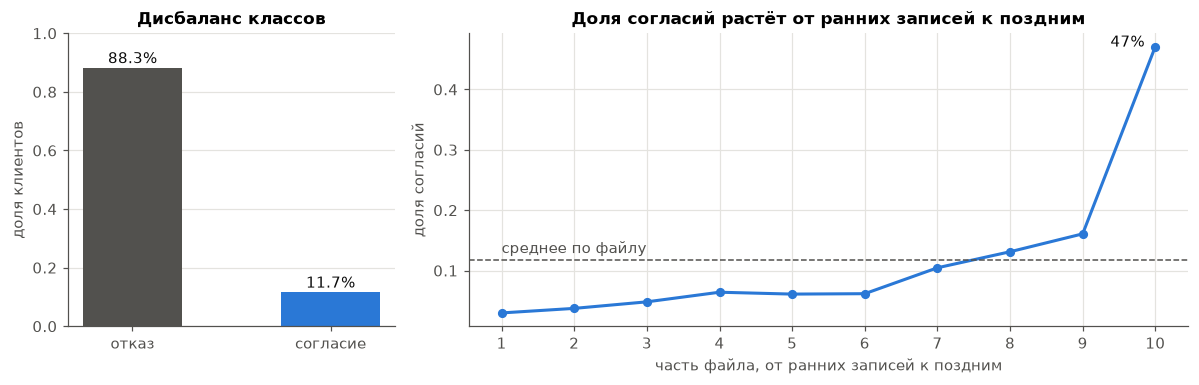

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2.2]})

shares = raw["y"].value_counts(normalize=True).reindex(["no", "yes"])       # доли классов
axes[0].bar(["отказ", "согласие"], shares.values, color=[MUTED, BLUE], width=0.5)
for i, v in enumerate(shares.values):                                       # подпись над столбцом
    axes[0].text(i, v + 0.015, f"{v:.1%}", ha="center", color=INK)
axes[0].set(title="Дисбаланс классов", ylabel="доля клиентов", ylim=(0, 1))
axes[0].grid(axis="x", visible=False)

# Строки идут по порядку дат: делим файл на 10 равных частей
decile = pd.Series(np.arange(len(raw)) * 10 // len(raw), name="часть файла") + 1
drift = (raw["y"] == "yes").groupby(decile).mean()
axes[1].plot(drift.index, drift.values, color=BLUE, marker="o", markersize=5)
axes[1].axhline((raw["y"] == "yes").mean(), color=MUTED, linestyle="--", linewidth=1)
axes[1].text(1, (raw["y"] == "yes").mean() + 0.012, "среднее по файлу", color=MUTED)
axes[1].text(drift.index[-1] - 0.15, drift.values[-1], f"{drift.values[-1]:.0%}", ha="right", color=INK)
axes[1].set(title="Доля согласий растёт от ранних записей к поздним", xlabel="часть файла, от ранних записей к поздним",
            ylabel="доля согласий", xticks=range(1, 11))
fig.tight_layout()
print(save(fig, FIGURES, "01_balance_and_drift").name)
print(drift.round(3).to_string())
plt.show()

**Вывод.** Ожидание подтвердилось сильнее, чем предполагалось. Доля согласий растёт с 3.0% в начале файла до 47.1% в последней десятой части. Данные нестационарны, поэтому после основного сравнения обязательна отдельная проверка по времени (раздел 11).

### 3.2. Числовые признаки

**Ожидания.** Возраст близок к нормальному с хвостом. Баланс, `campaign` и `previous` имеют длинный правый хвост. `duration` сильно разделяет классы, потому что долгий разговор это и есть почти согласие.

02_numeric_distributions.png


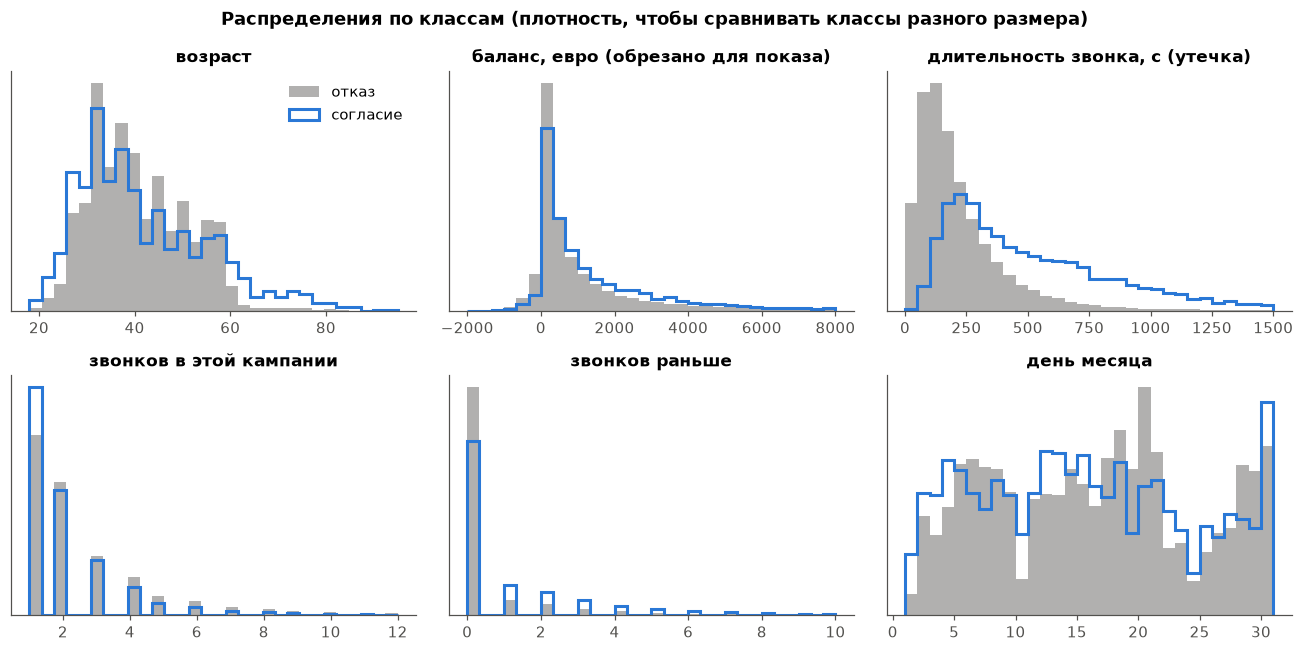

Асимметрия: {'age': 0.68, 'balance': 8.36, 'duration': 3.14, 'campaign': 4.9, 'pdays': 2.62, 'previous': 41.85, 'day': 0.09}


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
yes, no = raw["y"] == "yes", raw["y"] == "no"                     # маски классов
panels = [("age", (18, 95), "возраст"), ("balance", (-2000, 8000), "баланс, евро (обрезано для показа)"),
          ("duration", (0, 1500), "длительность звонка, с (утечка)"), ("campaign", (1, 12), "звонков в этой кампании"),
          ("previous", (0, 10), "звонков раньше"), ("day", (1, 31), "день месяца")]
for ax, (col, rng, title) in zip(axes.ravel(), panels):
    ax.hist(raw.loc[no, col], bins=30, range=rng, density=True, color=MUTED, alpha=0.45, label="отказ")
    ax.hist(raw.loc[yes, col], bins=30, range=rng, density=True, histtype="step", color=BLUE, linewidth=2, label="согласие")
    ax.set(title=title, yticks=[])
    ax.grid(False)
axes[0, 0].legend()
fig.suptitle("Распределения по классам (плотность, чтобы сравнивать классы разного размера)", fontweight="bold")
fig.tight_layout()
print(save(fig, FIGURES, "02_numeric_distributions").name)
plt.show()

skew = raw[["age", "balance", "duration", "campaign", "pdays", "previous", "day"]].skew().round(2)
print("Асимметрия:", skew.to_dict())

**Вывод.** Хвосты подтвердились: асимметрия у `previous` 41.85, у `balance` 8.36, у `campaign` 4.9. Это причина логарифмов в разделе 4. У согласившихся чаще встречаются молодые и люди старше 60 лет, зависимость от возраста не линейная. `duration` разделяет классы лучше всех, но она известна только после звонка, поэтому использовать её нельзя. `day` почти не разделяет классы.

### 3.3. Категориальные признаки

**Ожидания.** Успех прошлой кампании сильно повышает шанс. Студенты и пенсионеры соглашаются чаще. Месяц влияет, но часть эффекта может быть не сезонностью, а изменением кампании со временем.

03_categorical_rates.png


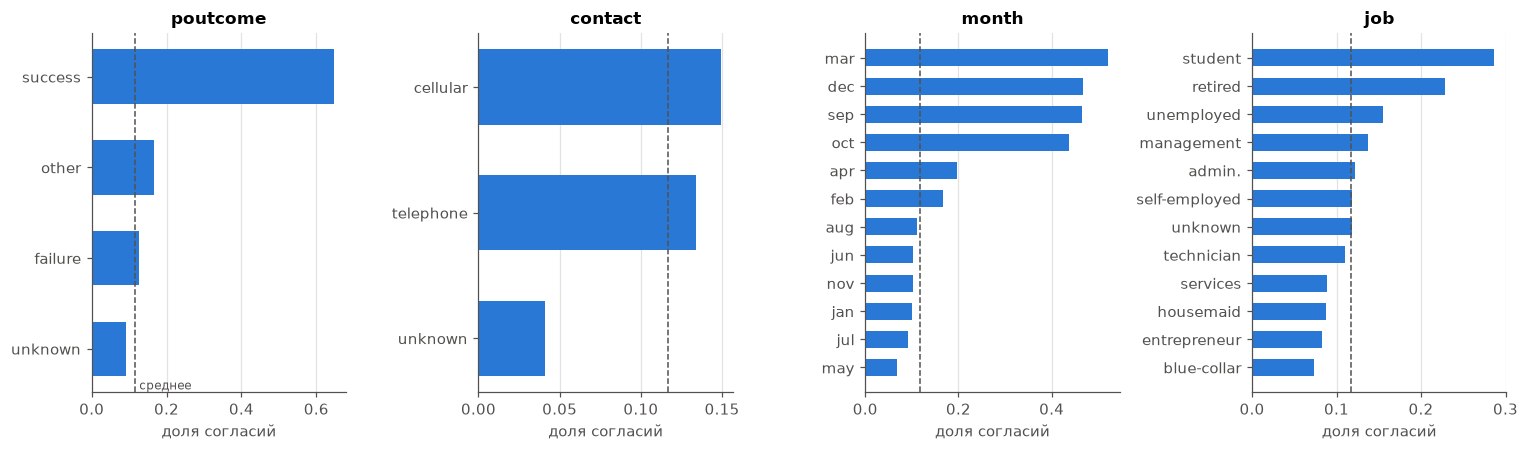

,клиентов,доля
month,,
may,13766,0.067
jul,6895,0.091
aug,6247,0.110
jun,5341,0.102
nov,3970,0.102
apr,2932,0.197
feb,2649,0.166
jan,1403,0.101
oct,738,0.438


,клиентов,доля
age,,
"(17, 25]",1336,0.240
"(25, 30]",5694,0.145
"(30, 40]",17687,0.102
"(40, 50]",11239,0.091
"(50, 60]",8067,0.101
"(60, 70]",701,0.405
"(70, 100]",487,0.448


month,apr,jul,nov,may,feb,jun,jan,aug,mar,oct,dec,sep
доля поздних строк в месяце,0.073,0.075,0.094,0.113,0.133,0.16,0.162,0.165,0.459,0.892,0.939,1.0


,доля_согласий,клиентов
поздние 15% строк,,
False,0.052,28290
True,0.329,3959


In [5]:
base = (raw["y"] == "yes").mean()                                     # средняя доля согласий
fig, axes = plt.subplots(1, 4, figsize=(14, 4.2))
for ax, col in zip(axes, ["poutcome", "contact", "month", "job"]):
    table = raw.groupby(col)["y"].agg(rate=lambda s: (s == "yes").mean(), n="size").sort_values("rate")
    ax.barh(table.index, table["rate"], color=BLUE, height=0.6)
    ax.axvline(base, color=MUTED, linestyle="--", linewidth=1)
    ax.set(title=col, xlabel="доля согласий")
    ax.grid(axis="y", visible=False)
axes[0].text(base + 0.01, -0.45, "среднее", color=MUTED, fontsize=8)
fig.tight_layout()
print(save(fig, FIGURES, "03_categorical_rates").name)
plt.show()
display(raw.groupby("month")["y"].agg(клиентов="size", доля=lambda s: round((s == "yes").mean(), 3)).sort_values("клиентов", ascending=False))
display(raw.groupby(pd.cut(raw["age"], [17, 25, 30, 40, 50, 60, 70, 100]), observed=True)["y"]
        .agg(клиентов="size", доля=lambda s: round((s == "yes").mean(), 3)))

# Месяц или период? Сравниваем одни и те же месяцы в ранних и поздних записях
is_late = pd.Series(np.arange(len(raw)) >= int(len(raw) * 0.85), index=raw.index, name="поздние 15% строк")
display(is_late.groupby(raw["month"]).mean().round(3).sort_values().rename("доля поздних строк в месяце").to_frame().T)
summer = raw["month"].isin(["may", "jun", "jul", "aug"])                 # месяцы, которые есть в обоих периодах
display((raw.loc[summer, "y"] == "yes").groupby(is_late[summer]).agg(доля_согласий="mean", клиентов="size").round(3))

**Вывод.** Успех прошлой кампании даёт 64.7% согласий при среднем 11.7%. Студенты (28.7%) и пенсионеры (22.8%) выше среднего, возраст U-образный: 24.0% до 25 лет, 9.1% в 40–50 лет, 40.5% в 60–70 лет. **Главное наблюдение:** высокие доли в марте, сентябре, октябре и декабре это не только сезонность. Строки за сентябрь, октябрь и декабрь почти целиком лежат в конце файла, а в одних и тех же месяцах май–август доля согласий у ранних записей 5.2%, у поздних 32.9%. Месяц частично заменяет собой период.

### 3.4. Корреляции

**Ожидания.** Сильнее всего с целью связана `duration`. `pdays` и `previous` связаны между собой, потому что описывают один факт: был ли контакт раньше.

04_correlations.png


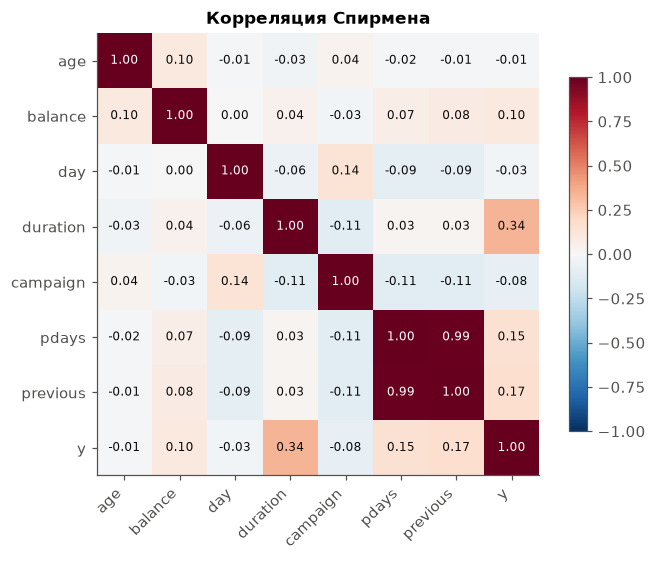

In [6]:
numeric = raw[["age", "balance", "day", "duration", "campaign", "pdays", "previous"]].assign(y=(raw["y"] == "yes").astype(int))
corr = numeric.corr(method="spearman")                                # Спирмен устойчив к длинным хвостам
fig, ax = plt.subplots(figsize=(6.5, 5.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)                  # расходящаяся шкала с нейтральным нулём
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(v) > 0.6 else INK)
ax.set_title("Корреляция Спирмена")
fig.colorbar(im, shrink=0.8)
fig.tight_layout()
print(save(fig, FIGURES, "04_correlations").name)
plt.show()

**Вывод.** С целью сильнее всего связана `duration` (0.34), это та самая утечка. Остальные связи слабые: `previous` 0.17, `pdays` 0.15, `balance` 0.10. `pdays` и `previous` дублируют друг друга (0.99), как и ожидалось. Слабые попарные корреляции говорят, что простого правила нет, но нелинейные связи и взаимодействия они не показывают.

### 3.5. Выбросы

**Ожидания.** Выбросы есть в `balance`, `campaign`, `previous`. Удалять их автоматически нельзя: сначала надо понять, ошибка это или редкое, но настоящее значение.

In [7]:
cols = ["age", "balance", "campaign", "previous"]
q1, q3 = raw[cols].quantile(0.25), raw[cols].quantile(0.75)            # квартили
is_out = (raw[cols] < q1 - 1.5 * (q3 - q1)) | (raw[cols] > q3 + 1.5 * (q3 - q1))  # правило 1.5 IQR
display(pd.DataFrame({
    "выбросов": is_out.sum(), "доля": is_out.mean().round(3),
    "доля согласий у выбросов": [round((raw.loc[is_out[c], "y"] == "yes").mean(), 3) for c in cols],
    "максимум": raw[cols].max(),
}))
print("Самые большие previous:", raw["previous"].nlargest(5).tolist())
display(raw.nlargest(1, "previous")[["age", "job", "balance", "campaign", "pdays", "previous", "poutcome", "y"]])

,выбросов,доля,доля согласий у выбросов,максимум
age,487,0.011,0.448,95
balance,4729,0.105,0.162,102127
campaign,3064,0.068,0.053,63
previous,8257,0.183,0.231,275


Самые большие previous: [275, 58, 55, 51, 41]


,age,job,balance,campaign,pdays,previous,poutcome,y
29182,40,management,543,2,262,275,other,no


**Вывод.** Ничего не удаляем. Выбросы по возрасту (доля согласий 44.8%) и по `previous` (23.1%) это самые ценные клиенты, а не ошибки. Значение `previous = 275` при следующем значении 58 выглядит подозрительно, но подтвердить ошибку нечем, поэтому строка остаётся, а логарифм ограничивает её влияние.

## 4. Предобработка и feature engineering

*2026-11-06. Цель: убрать утечку, создать новые признаки, разделить данные, обучить преобразования только на train.*

| Решение | Почему |
|---|---|
| Удаляем `duration` | Длительность звонка известна только после звонка. Это data leakage (утечка данных), что прямо сказано в описании датасета |
| `unknown` оставляем отдельной категорией | Отсутствие сведений само несёт сигнал: у `contact = unknown` доля согласий ниже |
| `pdays = -1` → флаг `was_contacted_before` и `recency` | Как число −1 бессмысленно, оно означало бы «меньше нуля дней назад» |
| `balance`, `campaign`, `previous` → логарифм | Сжимает хвосты. Нейросети и логрегрессия учатся стабильнее, выбросы не удаляются |
| `is_young_or_senior` | Зависимость от возраста U-образная, линейная модель сама её не увидит |
| `has_any_loan`, `is_negative_balance` | Простые бизнес-флаги о кредитной нагрузке |
| StandardScaler и OneHotEncoder | Обучаются только на train, поэтому среднее и категории из теста не попадают в модель |

,сплит,строк,согласий,доля
0,train,31647,3702,0.117
1,val,6782,794,0.117
2,test,6782,793,0.117


,balance,balance_slog,is_negative_balance,pdays,was_contacted_before,recency,campaign,campaign_log,age,is_young_or_senior,housing,loan,has_any_loan
26704,31,3.466,0,181,1,0.005,2,1.099,39,0,yes,no,1
38066,97,4.585,0,-1,0,0.000,3,1.386,34,0,no,no,0
37881,499,6.215,0,339,1,0.003,1,0.693,32,0,yes,no,1
18894,0,0.000,0,-1,0,0.000,1,0.693,36,0,no,no,0
32642,1143,7.042,0,317,1,0.003,1,0.693,48,0,yes,no,1


Матрица для моделей: (31647, 54) | среднее первых числовых: [ 0.  0. -0.] | std: [1. 1. 1.]


,age,day,balance_slog,campaign_log,previous_log,recency,is_negative_balance,was_contacted_before,is_young_or_senior,has_any_loan,job_admin.,job_blue-collar
0,-0.93,-0.82,-1.11,-0.91,-0.42,-0.12,-0.3,-0.47,-0.27,0.78,0.0,0.0
1,-0.55,0.14,0.10,-0.91,-0.42,-0.12,-0.3,-0.47,-0.27,0.78,0.0,0.0
2,-1.59,0.02,-0.14,-0.12,-0.42,-0.12,-0.3,-0.47,3.66,0.78,0.0,1.0


05_balance_transform.png


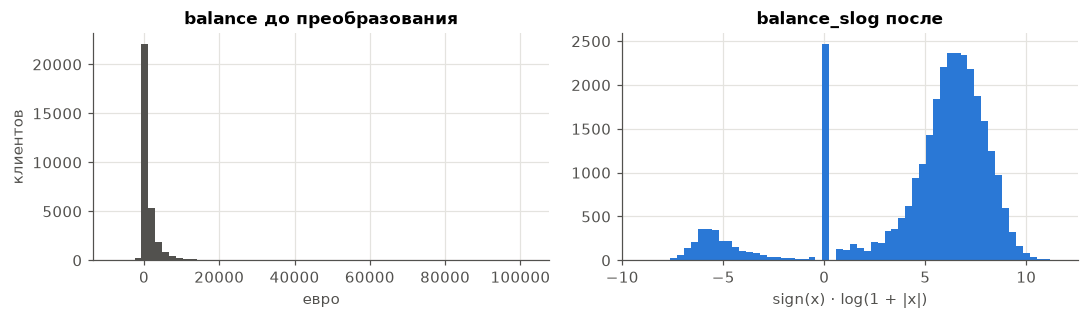

In [8]:
X, y = load_data(ROOT)                                                     # X без duration и y
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)          # 70/15/15 со stratify
split_table = split_summary({"train": y_train, "val": y_val, "test": y_test})
split_table.to_csv(TABLES / "splits.csv", index=False)
display(split_table)

new_cols = ["balance", "balance_slog", "is_negative_balance", "pdays", "was_contacted_before", "recency",
            "campaign", "campaign_log", "age", "is_young_or_senior", "housing", "loan", "has_any_loan"]
display(add_features(X_train).sample(5, random_state=SEED)[new_cols].round(3))     # превью новых признаков

prep = build_preprocessor("engineered")                                    # схема предобработки
A_train = prep.fit_transform(X_train, y_train)                             # учится только на train
A_val, A_test = prep.transform(X_val), prep.transform(X_test)              # только применяется
names = feature_names(prep)
print("Матрица для моделей:", A_train.shape, "| среднее первых числовых:", A_train[:, :3].mean(axis=0).round(4),
      "| std:", A_train[:, :3].std(axis=0).round(4))
display(pd.DataFrame(A_train[:3], columns=names).iloc[:, :12].round(2))   # превью после обработки

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].hist(X_train["balance"], bins=60, color=MUTED)
axes[0].set(title="balance до преобразования", ylabel="клиентов", xlabel="евро")
axes[1].hist(add_features(X_train)["balance_slog"], bins=60, color=BLUE)
axes[1].set(title="balance_slog после", xlabel="sign(x) · log(1 + |x|)")
fig.tight_layout()
print(save(fig, FIGURES, "05_balance_transform").name)
plt.show()

**Вывод.** Разбиение сохранило долю согласий 0.117 во всех частях. После обработки 54 столбца: 10 числовых и 44 one-hot. Среднее на train равно 0, std равно 1, значит scaler сработал. Логарифм превратил хвост баланса в читаемое распределение, пик в нуле это клиенты с нулевым балансом.

## 5. Baseline и логистическая регрессия

*2026-11-06. Цель: задать нижнюю планку и настроить первую модель.*

**Baseline.** Dummy с постоянной вероятностью означает «звонить всем подряд». Его PR-AUC равна доле согласий.

**Ожидания.** Логрегрессия заметно лучше baseline, но ограничена линейной границей. C подбираем через GridSearchCV внутри Pipeline, чтобы scaler обучался заново на каждом фолде.

Dummy val: {'PR-AUC': 0.117, 'ROC-AUC': 0.5, 'F1': 0.21, 'Recall': 1.0}


,C,CV PR-AUC,std
0,0.001,0.3449,0.0128
1,0.010,0.3964,0.0161
2,0.100,0.4061,0.0188
3,1.000,0.4063,0.0193
4,10.000,0.4063,0.0193


Лучший C: 1 | val PR-AUC: 0.4278 | время, с: 0.24


06_logreg_coefficients.png


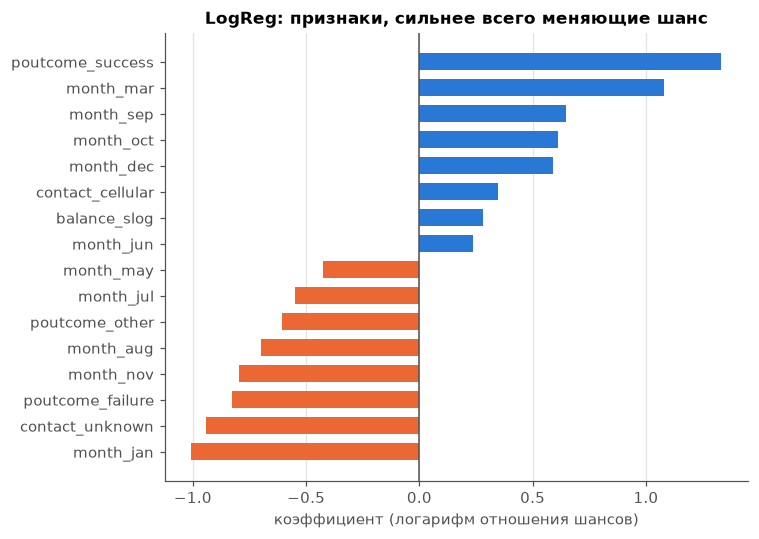

In [9]:
results_val = {}                                                            # сюда складываем модели и их оценки на val

dummy = DummyClassifier(strategy="prior").fit(A_train, y_train)             # всегда даёт долю согласий из train
p = proba(dummy, A_val)
results_val["Dummy"] = {"model": dummy, "threshold": 0.0, "time": 0.0}      # порог 0: звоним всем
print("Dummy val:", {k: round(v, 3) for k, v in evaluate(y_val, p, 0.0).items() if k in ["PR-AUC", "ROC-AUC", "F1", "Recall"]})

search = GridSearchCV(
    Pipeline([("prep", build_preprocessor("engineered")), ("model", LogisticRegression(max_iter=2000))]),
    {"model__C": [0.001, 0.01, 0.1, 1, 10]},        # C обратна силе регуляризации
    scoring="average_precision", cv=5,               # PR-AUC на 5 фолдах train
).fit(X_train, y_train)
lr_grid = pd.DataFrame(search.cv_results_)[["param_model__C", "mean_test_score", "std_test_score"]].round(4)
lr_grid.columns = ["C", "CV PR-AUC", "std"]
lr_grid.to_csv(TABLES / "logreg_grid.csv", index=False)
display(lr_grid)
best_C = search.best_params_["model__C"]

logreg, t = fit_timed(LogisticRegression(C=best_C, max_iter=2000), A_train, y_train)  # финальная модель
results_val["LogReg"] = {"model": logreg, "threshold": best_threshold(y_val, proba(logreg, A_val)), "time": t}
print("Лучший C:", best_C, "| val PR-AUC:", round(average_precision_score(y_val, proba(logreg, A_val)), 4), "| время, с:", round(t, 2))

coefs = pd.Series(logreg.coef_[0], index=names).sort_values()              # веса на стандартизованных данных
top = pd.concat([coefs.head(8), coefs.tail(8)])
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top.values, color=[ORANGE if v < 0 else BLUE for v in top.values], height=0.65)
ax.axvline(0, color=MUTED, linewidth=1)
ax.set(title="LogReg: признаки, сильнее всего меняющие шанс", xlabel="коэффициент (логарифм отношения шансов)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
print(save(fig, FIGURES, "06_logreg_coefficients").name)
plt.show()

**Вывод.** Логрегрессия подняла PR-AUC с 0.117 у Dummy до 0.428 на val. C от 0.1 и выше не меняет результат: данных много, а параметров мало, регуляризация почти не нужна. Самый сильный признак `poutcome_success`. Много сильных коэффициентов у месяцев, и это предупреждение: модель частично выучила период, а не поведение клиентов (см. раздел 3.3).

## 6. MLP из sklearn

*2026-11-06. Цель: добавить нелинейность и проверить, что она даёт.*

**Ожидания.** Небольшой прирост к логрегрессии: в задаче мало чистого сигнала, а один запуск сети зависит от seed. Поэтому каждая конфигурация оценивается на val как среднее по 3 seed. Сеть училась на тех же признаках, размер батча 256, Adam, early stopping на внутренних 10% train.

In [10]:
SEEDS = [42, 7, 2026]                                                       # seed для усреднения при подборе

def search_grid(make_model, grid):
    """Обучает каждую конфигурацию на нескольких seed и считает PR-AUC на val."""
    rows = []
    for params in grid:
        scores = []
        for seed in SEEDS:
            model = make_model(params, seed).fit(A_train, y_train)
            scores.append(average_precision_score(y_val, proba(model, A_val)))
        rows.append({**params, "val PR-AUC": np.mean(scores), "std": np.std(scores)})
    return pd.DataFrame(rows).sort_values("val PR-AUC", ascending=False).reset_index(drop=True)

def make_sk(params, seed):
    return MLPClassifier(params["hidden"], alpha=params["alpha"], batch_size=256, learning_rate_init=1e-3,
                         max_iter=200, early_stopping=True, n_iter_no_change=10, random_state=seed)

sk_grid = search_grid(make_sk, [{"hidden": h, "alpha": a}
                                for h in [(32,), (32, 16), (64, 32), (128, 64), (64, 32, 16)]
                                for a in [1e-4, 1e-2, 0.25, 1.0]])
sk_grid.round(4).to_csv(TABLES / "sklearn_mlp_grid.csv", index=False)
display(sk_grid.head(8).round(4))

sk_best = sk_grid.iloc[0].to_dict()
sk_model, t = fit_timed(make_sk(sk_best, SEED), A_train, y_train)
results_val["sklearn MLP"] = {"model": sk_model, "threshold": best_threshold(y_val, proba(sk_model, A_val)), "time": t}
print("Лучшая конфигурация:", sk_best["hidden"], "alpha =", sk_best["alpha"], "| эпох:", sk_model.n_iter_, "| время, с:", round(t, 2))

,hidden,alpha,val PR-AUC,std
0,"(32, 16)",0.2500,0.4507,0.0065
1,"(64, 32, 16)",0.2500,0.4503,0.0070
2,"(64, 32)",0.0001,0.4496,0.0023
3,"(64, 32, 16)",0.0001,0.4474,0.0036
4,"(128, 64)",0.2500,0.4467,0.0085
5,"(64, 32)",0.0100,0.4466,0.0036
6,"(128, 64)",0.0001,0.4464,0.0058
7,"(64, 32, 16)",0.0100,0.4439,0.0023


Лучшая конфигурация: (32, 16) alpha = 0.25 | эпох: 25 | время, с: 2.81


**Вывод.** Лучшая конфигурация (32, 16), alpha = 0.25, но первые три места различаются меньше чем на 0.002, а разброс от seed 0.002–0.007. Это ничья, а не найденный оптимум. Нелинейность дала прирост к логрегрессии: 0.451 против 0.428 на val.

## 7. Своя нейросеть на numpy

*2026-11-06. Цель: написать сеть с 2–3 скрытыми слоями только на numpy. Код: [`src/numpy_mlp.py`](../src/numpy_mlp.py).*

Внутри: инициализация He, ReLU (или tanh), прямой проход, бинарная кросс-энтропия через логит, ручной backpropagation, Adam, L2, мини-батчи, early stopping с возвратом лучших весов.

### 7.1. Проверка градиента

Если backprop написан с ошибкой, сеть всё равно часто обучается, но хуже, и это незаметно. Поэтому сверяем его с численной производной: (L(θ+ε) − L(θ−ε)) / 2ε.

In [11]:
checks = []
for hidden, act in [((8, 4), "relu"), ((8, 4, 3), "relu"), ((8, 4, 3), "tanh")]:
    net = NumpyMLP(hidden, activation=act, l2=1e-3)                       # необученная сеть
    rng = np.random.default_rng(SEED)
    net._init_params(A_train.shape[1], rng)                               # случайные веса
    # При b = 0 и выключенном предыдущем слое z равно ровно 0, а в этой точке у ReLU нет производной.
    # Маленькие ненулевые сдвиги уводят проверку от излома: сверять там просто нечего
    for b in net.b_:
        b += rng.normal(0, 0.01, b.shape)
    error = gradient_check(net, A_train[:30], y_train.values[:30].astype(float))
    checks.append({"слои": hidden, "активация": act, "относительная ошибка": error})
display(pd.DataFrame(checks))
assert max(c["относительная ошибка"] for c in checks) < 1e-6              # упадём, если backprop неверный

,слои,активация,относительная ошибка
0,"(8, 4)",relu,5.179847e-10
1,"(8, 4, 3)",relu,7.337697e-10
2,"(8, 4, 3)",tanh,8.790555e-10


**Вывод.** Относительная ошибка меньше 1e-9 на всех сетях, значит ручной backprop верный. Первая версия проверки падала на ReLU-сети из 3 слоёв. Причина оказалась не в коде обучения: при нулевых сдвигах и выключенном предыдущем слое z равно ровно 0, а там у ReLU нет производной. В коде на этот случай принято значение 0, это допустимая субпроизводная.

### 7.2. Один шаг руками: forward и backpropagation

Самая маленькая сеть с двумя скрытыми слоями: вход 2 → слой 1 из 2 нейронов (ReLU) → слой 2 из 1 нейрона (ReLU) → выход с sigmoid. Значения весов заданы вручную, чтобы весь расчёт можно было повторить на бумаге.

In [12]:
x = np.array([1.0, 2.0]); target = 1.0                  # один объект: признаки и правильный ответ
W1 = np.array([[0.5, 0.2], [0.1, 0.3]]); b1 = np.array([0.0, 0.1])  # строка = входной признак, столбец = нейрон
W2 = np.array([[0.4], [-0.1]]);          b2 = np.array([0.2])
W3 = np.array([[0.8]]);                  b3 = np.array([-0.1])
lr = 0.1                                                 # шаг обычного градиентного спуска

# ---------- Прямой проход ----------
z1 = x @ W1 + b1;   a1 = np.maximum(z1, 0)               # слой 1: линейная часть и ReLU
z2 = a1 @ W2 + b2;  a2 = np.maximum(z2, 0)               # слой 2
z3 = a2 @ W3 + b3                                        # выход: логит
p = 1 / (1 + np.exp(-z3))                                # sigmoid
loss = -(target * np.log(p) + (1 - target) * np.log(1 - p)).item()  # кросс-энтропия
print("z1 =", z1.round(4), "a1 =", a1.round(4))
print("z2 =", z2.round(4), "a2 =", a2.round(4))
print("z3 =", z3.round(4), "p =", p.round(4), "loss =", round(loss, 4))

# ---------- Обратный проход ----------
d3 = p - target                                          # dL/dz3 = p - y
gW3, gb3 = d3 * a2, d3                                   # dz3/dW3 = a2, dz3/db3 = 1
da2 = d3 * W3.ravel()                                    # ошибка на выходе слоя 2
d2 = da2 * (z2 > 0)                                      # через ReLU: 1, если нейрон активен
gW2, gb2 = np.outer(a1, d2), d2                          # dz2/dW2 = a1
da1 = d2 @ W2.T                                          # ошибка на выходе слоя 1
d1 = da1 * (z1 > 0)                                      # через ReLU
gW1, gb1 = np.outer(x, d1), d1                           # dz1/dW1 = x
print("d3 =", d3.round(4), "| dL/dW3 =", gW3.round(4), "| dL/db3 =", gb3.round(4))
print("d2 =", d2.round(4), "| dL/dW2 =", gW2.ravel().round(4), "| dL/db2 =", gb2.round(4))
print("d1 =", d1.round(4), "| dL/dW1 =", gW1.round(4).tolist(), "| dL/db1 =", gb1.round(4))

# ---------- Сверка с классом NumpyMLP и шаг обновления ----------
net = NumpyMLP((2, 1), l2=0.0)                           # та же архитектура
net.W_, net.b_ = [W1.copy(), W2.copy(), W3.copy()], [b1.copy(), b2.copy(), b3.copy()]
logit, cache = net._forward(x[None, :])
gW, gb = net._backward(logit, np.array([target]), cache)
assert np.allclose(gW[0], gW1) and np.allclose(gW[1], gW2) and np.allclose(gW[2], gW3)  # ручной расчёт совпал с классом
assert np.allclose(gb[0], gb1) and np.allclose(gb[1], gb2) and np.allclose(gb[2], gb3)
for param, grad in zip(net.W_ + net.b_, gW + gb):
    param -= lr * grad                                   # один шаг градиентного спуска
new_logit, _ = net._forward(x[None, :])
new_p = 1 / (1 + np.exp(-new_logit))
print("Новые W1:", net.W_[0].round(4).tolist(), "| новые b1:", net.b_[0].round(4).tolist())
print("Новые W2:", net.W_[1].ravel().round(4).tolist(), "| новый b2:", net.b_[1].round(4).tolist())
print("Новый W3:", net.W_[2].round(4).tolist(), "| новый b3:", net.b_[2].round(4).tolist())
print("После шага: p =", new_p.round(4), "loss =", round(-np.log(new_p).item(), 4))

z1 = [0.7 0.9] a1 = [0.7 0.9]
z2 = [0.39] a2 = [0.39]
z3 = [0.212] p = [0.5528] loss = 0.5928
d3 = [-0.4472] | dL/dW3 = [-0.1744] | dL/db3 = [-0.4472]
d2 = [-0.3578] | dL/dW2 = [-0.2504 -0.322 ] | dL/db2 = [-0.3578]
d1 = [-0.1431  0.0358] | dL/dW1 = [[-0.1431, 0.0358], [-0.2862, 0.0716]] | dL/db1 = [-0.1431  0.0358]
Новые W1: [[0.5143, 0.1964], [0.1286, 0.2928]] | новые b1: [0.0143, 0.0964]
Новые W2: [0.425, -0.0678] | новый b2: [0.2358]
Новый W3: [[0.8174]] | новый b3: [-0.0553]
После шага: p = [0.5895] loss = 0.5285


**Вывод.** Ручной расчёт совпал с `NumpyMLP` (проверяют два `assert`). После одного шага вероятность правильного класса выросла с 0.5528 до 0.5895, а loss упал с 0.5928 до 0.5285: шаг идёт в нужную сторону.

### 7.3. Подбор архитектуры и обучение

**Ожидания.** 2 и 3 скрытых слоя дадут близкий результат. Сила L2 важнее глубины, потому что признаков мало и сеть легко переобучается.

,hidden,l2,lr,val PR-AUC,std
0,"(64, 32)",0.0010,0.001,0.4568,0.0028
1,"(32, 16)",0.0010,0.001,0.4542,0.0021
2,"(64, 32, 16)",0.0010,0.001,0.4512,0.0066
3,"(128, 64)",0.0010,0.001,0.4508,0.0012
4,"(32, 16, 8)",0.0010,0.001,0.4500,0.0054
5,"(32, 16, 8)",0.0001,0.001,0.4491,0.0014
6,"(128, 64)",0.0000,0.001,0.4478,0.0033
7,"(32, 16, 8)",0.0000,0.001,0.4476,0.0030


Лучшая конфигурация: (64, 32) l2 = 0.001 | лучшая эпоха: 32 | время, с: 2.22


07_numpy_learning_curves.png


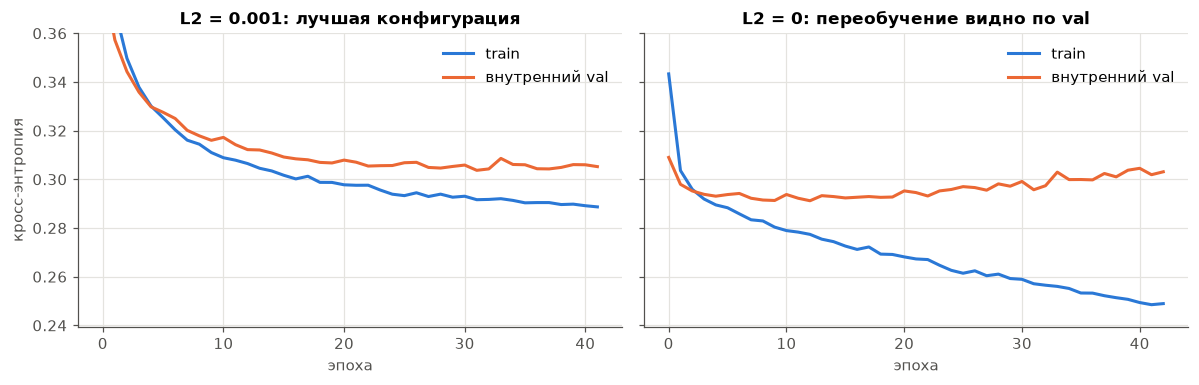

In [13]:
def make_np(params, seed):
    return NumpyMLP(params["hidden"], learning_rate=params["lr"], l2=params["l2"], random_state=seed)

np_grid = search_grid(make_np, [{"hidden": h, "l2": l, "lr": 1e-3}
                                for h in [(32, 16), (64, 32), (128, 64), (32, 16, 8), (64, 32, 16)]
                                for l in [0.0, 1e-4, 1e-3, 1e-2]])
np_grid.round(4).to_csv(TABLES / "numpy_mlp_grid.csv", index=False)
display(np_grid.head(8).round(4))

np_best = np_grid.iloc[0].to_dict()
np_model, t = fit_timed(make_np(np_best, SEED), A_train, y_train)
results_val["Numpy MLP"] = {"model": np_model, "threshold": best_threshold(y_val, proba(np_model, A_val)), "time": t}
print("Лучшая конфигурация:", np_best["hidden"], "l2 =", np_best["l2"], "| лучшая эпоха:", np_model.best_epoch_, "| время, с:", round(t, 2))

noreg = NumpyMLP(np_best["hidden"], l2=0.0, patience=30, max_epochs=60).fit(A_train, y_train)  # для сравнения: без L2

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, model, title in [(axes[0], np_model, f"L2 = {np_best['l2']}: лучшая конфигурация"), (axes[1], noreg, "L2 = 0: переобучение видно по val")]:
    ax.plot(model.history_["train_loss"], color=BLUE, label="train")
    ax.plot(model.history_["val_loss"], color=ORANGE, label="внутренний val")
    ax.set(title=title, xlabel="эпоха")
    ax.legend()
axes[0].set_ylabel("кросс-энтропия")
axes[0].set_ylim(top=0.36)
fig.tight_layout()
print(save(fig, FIGURES, "07_numpy_learning_curves").name)
plt.show()

**Вывод.** Сила L2 оказалась важнее глубины: все пять лучших конфигураций используют L2 = 0.001, а 2 и 3 слоя дают близкий результат. Лучшая сеть (64, 32), L2 = 0.001, val PR-AUC 0.457 ± 0.003. На графике видно зачем нужна L2: без неё train падает до 0.25, а val после 20-й эпохи растёт. Это переобучение, а с L2 разрыв намного меньше.

### 7.4. Что меняет активация (один эксперимент, одно изменение)

**Ожидания.** На такой неглубокой сети ReLU и tanh дадут близкий результат.

In [14]:
rows = []
for act in ["relu", "tanh"]:
    scores = [average_precision_score(y_val, proba(NumpyMLP(np_best["hidden"], activation=act, l2=np_best["l2"], random_state=s).fit(A_train, y_train), A_val)) for s in SEEDS]
    rows.append({"активация": act, "val PR-AUC": np.mean(scores), "std": np.std(scores)})
activation_table = pd.DataFrame(rows).round(4)
activation_table.to_csv(TABLES / "numpy_activation.csv", index=False)
display(activation_table)

,активация,val PR-AUC,std
0,relu,0.4568,0.0028
1,tanh,0.4476,0.0059


**Вывод.** ReLU немного лучше tanh: 0.4568 против 0.4476. Ожидание близкого результата в целом подтвердилось, разница около двух стандартных отклонений при трёх seed, поэтому вывод осторожный.

## 8. PyTorch (необязательный пункт 6)

*2026-11-06. Цель: независимо проверить свою сеть. Та же архитектура и те же параметры, но backprop считает autograd. Код: [`src/torch_mlp.py`](../src/torch_mlp.py). TensorFlow не использовался: он не установлен для Python 3.14, а вторая библиотека ничего не добавила бы к проверке.*

**Ожидания.** Результат в пределах разброса от seed. Большое отличие означало бы ошибку в своей сети.

In [15]:
torch_scores = [average_precision_score(y_val, proba(TorchMLP(np_best["hidden"], l2=np_best["l2"], random_state=s).fit(A_train, y_train), A_val)) for s in SEEDS]
numpy_scores = [average_precision_score(y_val, proba(make_np(np_best, s).fit(A_train, y_train), A_val)) for s in SEEDS]
print("Numpy   val PR-AUC:", round(np.mean(numpy_scores), 4), "±", round(np.std(numpy_scores), 4))
print("PyTorch val PR-AUC:", round(np.mean(torch_scores), 4), "±", round(np.std(torch_scores), 4))

torch_model, t = fit_timed(TorchMLP(np_best["hidden"], l2=np_best["l2"], random_state=SEED), A_train, y_train)
results_val["PyTorch MLP"] = {"model": torch_model, "threshold": best_threshold(y_val, proba(torch_model, A_val)), "time": t}
print("Время обучения, с:", round(t, 2))

Numpy   val PR-AUC: 0.4568 ± 0.0028
PyTorch val PR-AUC: 0.4566 ± 0.0017


Время обучения, с: 4.44


**Вывод.** PyTorch дал 0.4566 ± 0.0017, своя сеть 0.4568 ± 0.0028. Результат совпал в пределах разброса: это независимое подтверждение, что своя сеть написана верно. PyTorch здесь обучался дольше, вероятно, из-за накладных расходов autograd на маленькой сети (отдельно это не измерялось).

## 9. Абляция: что дали признаки и что сделала бы утечка

*2026-11-06. Цель: измерить вклад решений из раздела 4. Меняем одну вещь за раз, смотрим на val.*

**Ожидания.** Новые признаки дадут небольшой прирост, сильнее у логрегрессии, потому что сеть часть зависимостей находит сама. Добавление `duration` резко поднимет метрику, и это будет ложный успех.

In [16]:
def ablation_row(name, prep_args, make_model, seeds):
    """Заново обучает предобработку на train и оценивает модель на val."""
    local = build_preprocessor(prep_args["feature_set"], prep_args.get("extra", ()))
    source_train, source_val = prep_args.get("train", X_train), prep_args.get("val", X_val)
    a_tr, a_v = local.fit_transform(source_train, y_train), local.transform(source_val)
    scores = [average_precision_score(y_val, proba(make_model(s).fit(a_tr, y_train), a_v)) for s in seeds]
    return {"эксперимент": name, "признаков": a_tr.shape[1], "val PR-AUC": np.mean(scores), "std": np.std(scores)}

make_lr = lambda s: LogisticRegression(C=best_C, max_iter=2000)
make_net = lambda s: make_np(np_best, s)
full = load_raw(ROOT)                                                      # только для опыта с утечкой
with_leak = {"train": full.loc[X_train.index], "val": full.loc[X_val.index]}

ablation = pd.DataFrame([
    ablation_row("LogReg, исходные признаки", {"feature_set": "raw"}, make_lr, [SEED]),
    ablation_row("LogReg, с новыми признаками", {"feature_set": "engineered"}, make_lr, [SEED]),
    ablation_row("Numpy MLP, исходные признаки", {"feature_set": "raw"}, make_net, SEEDS),
    ablation_row("Numpy MLP, с новыми признаками", {"feature_set": "engineered"}, make_net, SEEDS),
    ablation_row("LogReg, новые признаки + duration (утечка)", {"feature_set": "engineered", "extra": ["duration"], **with_leak}, make_lr, [SEED]),
]).round(4)
ablation.to_csv(TABLES / "ablation.csv", index=False)
display(ablation)

,эксперимент,признаков,val PR-AUC,std
0,"LogReg, исходные признаки",50,0.4201,0.0000
1,"LogReg, с новыми признаками",54,0.4278,0.0000
2,"Numpy MLP, исходные признаки",50,0.4534,0.0048
3,"Numpy MLP, с новыми признаками",54,0.4568,0.0028
4,"LogReg, новые признаки + duration (утечка)",55,0.5681,0.0000


**Вывод.** Новые признаки дали мало, но честно: LogReg 0.420 → 0.428, Numpy MLP 0.453 → 0.457, причём у сети прирост в пределах разброса. Как и ожидалось, линейной модели они помогают сильнее, потому что сеть часть зависимостей строит сама. `duration` подняла бы PR-AUC до 0.568, но такая модель бесполезна: перед звонком длительность неизвестна.

## 10. Итоговое сравнение на тесте

*2026-11-06. Цель: один раз проверить все выбранные модели. Параметры и порог зафиксированы по train и val, после этого раздела ничего не менялось.*

**Ожидания.** Сети немного лучше логрегрессии, своя сеть рядом с библиотечными. Все модели намного лучше Dummy.

,PR-AUC,ROC-AUC,F1,Precision,Recall,Захват топ-20%,Порог,TP,FP,FN,TN,"Время, с"
Модель,,,,,,,,,,,,
Dummy,0.117,0.500,0.209,0.117,1.000,0.187,0.000,793,5989,0,0,0.00
LogReg,0.424,0.771,0.454,0.499,0.416,0.571,0.225,330,331,463,5658,0.24
sklearn MLP,0.436,0.784,0.480,0.456,0.507,0.602,0.213,402,479,391,5510,2.81
Numpy MLP,0.447,0.789,0.482,0.459,0.508,0.608,0.209,403,475,390,5514,2.22
PyTorch MLP,0.442,0.783,0.481,0.470,0.493,0.608,0.216,391,441,402,5548,4.44


,PR-AUC,ROC-AUC,F1,Порог
Модель,,,,
Dummy,0.117,0.500,0.210,0.000
LogReg,0.428,0.778,0.462,0.225
sklearn MLP,0.453,0.792,0.481,0.213
Numpy MLP,0.459,0.795,0.495,0.209
PyTorch MLP,0.456,0.798,0.486,0.216


08_test_comparison.png


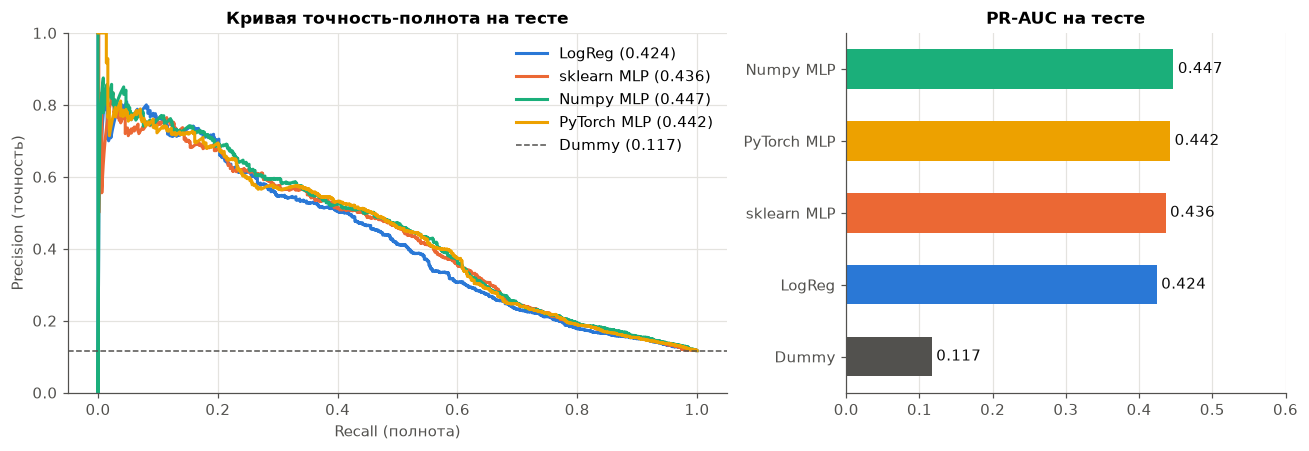

In [17]:
rows, test_proba = [], {}
for name, entry in results_val.items():
    p_test = proba(entry["model"], A_test)                                 # оценки на тесте
    test_proba[name] = p_test
    rows.append({"Модель": name, **evaluate(y_test, p_test, entry["threshold"]), "Время, с": round(entry["time"], 2)})
comparison = pd.DataFrame(rows).set_index("Модель")
comparison.round(3).to_csv(TABLES / "test_comparison.csv")
display(comparison.round(3))

val_rows = []
for name, entry in results_val.items():
    val_rows.append({"Модель": name, **evaluate(y_val, proba(entry["model"], A_val), entry["threshold"])})
val_comparison = pd.DataFrame(val_rows).set_index("Модель")
val_comparison.round(3).to_csv(TABLES / "val_comparison.csv")
display(val_comparison[["PR-AUC", "ROC-AUC", "F1", "Порог"]].round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
for name in ["LogReg", "sklearn MLP", "Numpy MLP", "PyTorch MLP"]:         # кривые точность-полнота
    prec, rec, _ = precision_recall_curve(y_test, test_proba[name])
    axes[0].plot(rec, prec, color=MODEL_COLORS[name], label=f"{name} ({comparison.loc[name, 'PR-AUC']:.3f})")
axes[0].axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1, label=f"Dummy ({y_test.mean():.3f})")
axes[0].set(title="Кривая точность-полнота на тесте", xlabel="Recall (полнота)", ylabel="Precision (точность)", ylim=(0, 1))
axes[0].legend()

order = comparison["PR-AUC"].sort_values()                                 # столбцы по метрике
axes[1].barh(order.index, order.values, color=[MODEL_COLORS[n] for n in order.index], height=0.55)
for i, v in enumerate(order.values):
    axes[1].text(v + 0.006, i, f"{v:.3f}", va="center", color=INK)
axes[1].set(title="PR-AUC на тесте", xlim=(0, 0.6))
axes[1].grid(axis="y", visible=False)
fig.tight_layout()
print(save(fig, FIGURES, "08_test_comparison").name)
plt.show()

**Вывод.** Все модели намного лучше Dummy. PR-AUC: Numpy MLP 0.447, PyTorch 0.442, sklearn 0.436, LogReg 0.424. Понятный смысл: если звонить только 20% лучших клиентов, Numpy MLP находит 60.8% всех согласий (примерно 482 из 793), логрегрессия 57.1% (примерно 453). При пороге 0.209 почти каждый второй звонок успешен (precision 0.459) против 0.117 при звонках всем. Падение с val 0.459 до теста 0.447 небольшое, сильного подгона под val нет.

### 10.1. Разница между моделями и разброс от seed

**Вопрос.** Реальна ли разница, или её может дать случайность? Бутстрап проверяет случайность выборки, повтор с другими seed проверяет случайность обучения.

,сравнение,разность,ДИ 2.5%,ДИ 97.5%
0,Numpy MLP − LogReg,0.0228,0.0059,0.0405
1,sklearn MLP − LogReg,0.0121,-0.0009,0.0241
2,Numpy MLP − sklearn MLP,0.0107,-0.0030,0.0249
3,Numpy MLP − PyTorch MLP,0.0045,-0.0049,0.0159


,Модель,PR-AUC среднее,std,мин,макс
0,sklearn MLP,0.4241,0.0129,0.4068,0.4423
1,Numpy MLP,0.4443,0.0036,0.4374,0.4474
2,PyTorch MLP,0.4432,0.0026,0.4394,0.4473


09_confusion_matrix.png


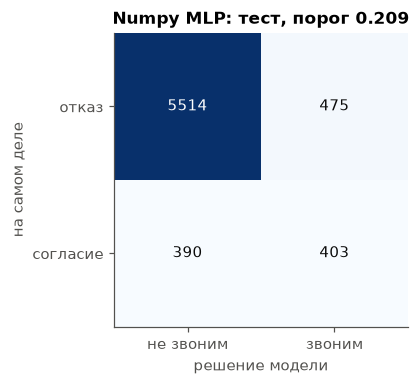

In [18]:
pairs = [("Numpy MLP", "LogReg"), ("sklearn MLP", "LogReg"), ("Numpy MLP", "sklearn MLP"), ("Numpy MLP", "PyTorch MLP")]
boot = pd.DataFrame([{"сравнение": f"{a} − {b}", **bootstrap_pr_auc_diff(y_test, test_proba[a], test_proba[b])} for a, b in pairs]).round(4)
boot.to_csv(TABLES / "bootstrap_diff.csv", index=False)
display(boot)

stability_seeds = [1, 2, 3, 4, 5]
stab = {
    "sklearn MLP": [average_precision_score(y_test, proba(make_sk(sk_best, s).fit(A_train, y_train), A_test)) for s in stability_seeds],
    "Numpy MLP": [average_precision_score(y_test, proba(make_np(np_best, s).fit(A_train, y_train), A_test)) for s in stability_seeds],
    "PyTorch MLP": [average_precision_score(y_test, proba(TorchMLP(np_best["hidden"], l2=np_best["l2"], random_state=s).fit(A_train, y_train), A_test)) for s in stability_seeds],
}
stability = pd.DataFrame([{"Модель": k, "PR-AUC среднее": np.mean(v), "std": np.std(v), "мин": np.min(v), "макс": np.max(v)} for k, v in stab.items()]).round(4)
stability.to_csv(TABLES / "seed_stability.csv", index=False)
display(stability)

best_name = comparison.drop(index="Dummy")["PR-AUC"].idxmax()              # лучшая на тесте, только для иллюстрации
row = comparison.loc[best_name]
matrix = np.array([[row["TN"], row["FP"]], [row["FN"], row["TP"]]], dtype=int)
fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(matrix, cmap="Blues")                                            # одна шкала: темнее значит больше
ax.set_xticks([0, 1], ["не звоним", "звоним"]); ax.set_yticks([0, 1], ["отказ", "согласие"])
ax.set(xlabel="решение модели", ylabel="на самом деле", title=f"{best_name}: тест, порог {row['Порог']:.3f}")
ax.grid(False)
for (i, j), v in np.ndenumerate(matrix):
    ax.text(j, i, f"{v}", ha="center", va="center", color="white" if v > matrix.max() / 2 else INK)
fig.tight_layout()
print(save(fig, FIGURES, "09_confusion_matrix").name)
plt.show()

**Вывод.** Преимущество Numpy MLP над логрегрессией подтверждается: разность 0.023, интервал [0.006; 0.041] не содержит 0. Для sklearn MLP интервал [−0.001; 0.024] содержит 0. Между тремя сетями один запуск победителя не определяет. По 5 seed Numpy и PyTorch совпадают (0.444 и 0.443), а sklearn MLP ниже и менее стабилен (0.424 ± 0.013). Вероятная, но не проверенная причина: early stopping в sklearn смотрит на accuracy, грубую при дисбалансе, а в своей сети на кросс-энтропию.

## 11. Диагностика: проверка по времени

*2026-11-06. Цель: узнать, сколько стоит допущение случайного разбиения из раздела 3.1. Модели с теми же параметрами учатся на первых 85% строк и проверяются на последних 15%. Никакой выбор по этой проверке не делается.*

**Ожидания.** PR-AUC сама по себе может вырасти, потому что положительных в конце намного больше. Поэтому сравниваем с Dummy этого же периода. ROC-AUC от доли положительных напрямую не зависит и должна упасть, если старые зависимости работают хуже.

,сплит,строк,согласий,доля
0,ранние 85%,38429,2621,0.068
1,поздние 15%,6782,2668,0.393


,PR-AUC,ROC-AUC
Модель,,
Dummy,0.393,0.500
LogReg,0.516,0.640
sklearn MLP,0.525,0.649
Numpy MLP,0.515,0.630
PyTorch MLP,0.523,0.641


,ROC-AUC случайное,ROC-AUC по времени
Модель,,
Dummy,0.500,0.500
LogReg,0.771,0.640
sklearn MLP,0.784,0.649
Numpy MLP,0.789,0.630
PyTorch MLP,0.783,0.641


10_temporal_check.png


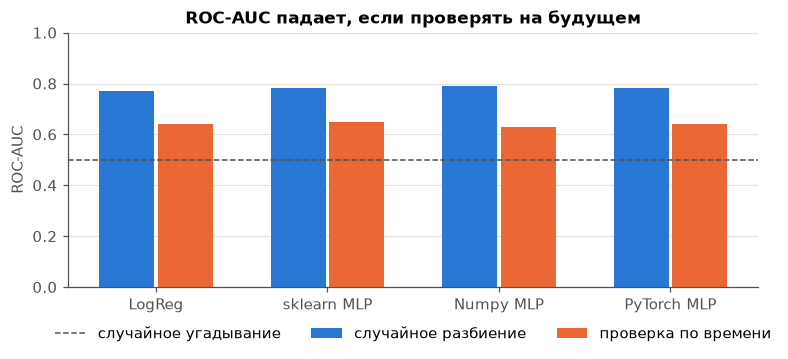

In [19]:
X_early, X_late, y_early, y_late = temporal_split(X, y)                    # разбиение по порядку строк
time_prep = build_preprocessor("engineered")                               # обучаем заново: только на ранних
A_early, A_late = time_prep.fit_transform(X_early, y_early), time_prep.transform(X_late)
display(split_summary({"ранние 85%": y_early, "поздние 15%": y_late}))

time_models = {
    "LogReg": LogisticRegression(C=best_C, max_iter=2000),
    "sklearn MLP": make_sk(sk_best, SEED),
    "Numpy MLP": make_np(np_best, SEED),
    "PyTorch MLP": TorchMLP(np_best["hidden"], l2=np_best["l2"], random_state=SEED),
}
rows = [{"Модель": "Dummy", "PR-AUC": y_late.mean(), "ROC-AUC": 0.5}]
for name, model in time_models.items():
    p_late = proba(model.fit(A_early, y_early), A_late)
    rows.append({"Модель": name, "PR-AUC": average_precision_score(y_late, p_late), "ROC-AUC": evaluate(y_late, p_late, 0.5)["ROC-AUC"]})
temporal = pd.DataFrame(rows).set_index("Модель").round(3)
temporal.to_csv(TABLES / "temporal_check.csv")
joined = comparison[["ROC-AUC"]].round(3).rename(columns={"ROC-AUC": "ROC-AUC случайное"}).join(temporal["ROC-AUC"].rename("ROC-AUC по времени"))
display(temporal); display(joined)

plot_table = joined.drop(index="Dummy")
pos = np.arange(len(plot_table))
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.bar(pos - 0.17, plot_table["ROC-AUC случайное"], 0.32, color=BLUE, label="случайное разбиение")
ax.bar(pos + 0.17, plot_table["ROC-AUC по времени"], 0.32, color=ORANGE, label="проверка по времени")
ax.axhline(0.5, color=MUTED, linestyle="--", linewidth=1, label="случайное угадывание")
ax.set_xticks(pos, plot_table.index)
ax.set(title="ROC-AUC падает, если проверять на будущем", ylabel="ROC-AUC", ylim=(0, 1))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", ncols=3, bbox_to_anchor=(0.5, -0.1))
fig.tight_layout()
print(save(fig, FIGURES, "10_temporal_check").name)
plt.show()

**Вывод.** Диагностика важнее всех предыдущих сравнений. ROC-AUC падает с 0.77–0.79 до 0.63–0.65, а порядок моделей меняется: sklearn MLP 0.649, PyTorch 0.641, LogReg 0.640, Numpy MLP 0.630. Разницы в 0.02 при одном запуске недостаточно, чтобы выбрать победителя. PR-AUC выросла до 0.52 только потому, что в этом периоде 39.3% согласий: прирост к Dummy 0.12–0.13 вместо 0.31–0.33. Значит, числа из раздела 10 показывают качество внутри того же периода, а не прогноз на будущее.

## 12. Итоговый вывод

*2026-11-06.*

1. **Задача решена:** все модели намного лучше наивной (PR-AUC 0.42–0.45 против 0.117), своя сеть на numpy с 2 скрытыми слоями работает наравне с библиотечными. Её корректность подтверждена проверкой градиента, ручным расчётом и совпадением с PyTorch.
2. **Лучшая по главной метрике на случайном разбиении:** Numpy MLP, PR-AUC 0.447, статистически лучше логрегрессии. Но прибавка небольшая: 60.8% согласий против 57.1% при 20% звонков.
3. **Что я бы выбирал на практике:** логрегрессию как рабочую версию (обучение меньше чем за секунду, понятные коэффициенты, на проверке по времени на уровне сетей) и сеть, только если эти 3.7 процентных пункта окупают сложность.
4. **Главное ограничение:** при проверке по времени ROC-AUC падает до 0.63–0.65. Данные нестационарны, поэтому в реальной работе модель надо регулярно переобучать и проверять именно по времени.
5. **Что ещё ограничивает вывод:** подбор шёл на val со случайным разбиением, `campaign`, `day`, `month` и `contact` описывают текущий контакт и должны быть известны заранее из плана кампании, а в данных нет года, поэтому время оценено только по порядку строк.

**Что где лежит.** Таблицы: `results/tables/`. Графики: `results/figures/`. Код: `src/`. Отчёт: `REPORT.ru.md`.

**Проверка человеком** в этой работе не нужна: выход моделей это вероятность, и она полностью оценивается метриками.